<a href="https://colab.research.google.com/github/munyeshyakajmv1/colab-git-assignment2-JMV/blob/main/Assignment5_EDA_Pandas_JMV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Assignment 5: Exploratory Data Analysis with Pandas**
Student Name: Jean Marie Vianney Munyeshyaka

Course name: Data Analytucs and Artificial Intelligence

Date: 21 November 2026

##**Objective**
The objective of this assignment is to perform Exploratory Data Analysis (EDA) using the Titanic dataset. The analysis includes data inspection, cleaning, feature engineering, visualization, and extracting meaningful insights using Pandas, Matplotlib, and Seaborn.

##Link to Colab and GitHub
Colab
https://colab.research.google.com/drive/1g8AyKWuWvJJ38ybzxPHgfL-l9QMDkmSr

GitHub
https://github.com/munyeshyakajmv1/colab-git-assignment2-JMV/blob/main/Assignment5_EDA_Pandas_JMV.ipynb

In [ ]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Improve plot appearance
sns.set_style("whitegrid")

##**Task 1: Load Titanic Dataset**
Load the Titanic dataset and verify that it has been imported successfully.

In [3]:
try:
    df = pd.read_csv("Titanic-Dataset.csv")

    print("Dataset Loaded Successfully")
    print("Shape:", df.shape)

except Exception as e:
    print("Error loading dataset:", e)

Dataset Loaded Successfully
Shape: (891, 12)


##**Task 2: Inspect the Dataset**
Inspect the dataset using:

###head()
###tail()
###dtypes
###describe()
This helps understand the structure and quality of the data before analysis.

In [4]:
try:
    print("First 5 Rows")
    display(df.head())

    print("\nLast 5 Rows")
    display(df.tail())

    print("\nData Types")
    print(df.dtypes)

    print("\nSummary Statistics")
    display(df.describe())

except Exception as e:
    print("Error:", e)

First 5 Rows


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Last 5 Rows


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q



Data Types
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

Summary Statistics


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


##**Task 3: Data Cleaning and Feature Engineering**
This section includes:

1. Creating passenger class categories.
2. Creating cabin categories.
3. Handling missing values in Age.
4. Creating a Family feature.



In [5]:
try:

    # Passenger class category

    df["PclassCategory"] = df["Pclass"].map({
        1: "First Class",
        2: "Second Class",
        3: "Third Class"
    })

    # Cabin category

    df["CabinCategory"] = df["Cabin"].fillna("Unknown")

    df["CabinCategory"] = df["CabinCategory"].apply(
        lambda x: x[0] if x != "Unknown" else "Unknown"
    )

    # Handle missing age values

    mean_age = df["Age"].mean()

    df["Age"] = df["Age"].fillna(mean_age)

    # Family feature

    df["Family"] = df["SibSp"] + df["Parch"]

    print("Missing Age Values Remaining:")
    print(df["Age"].isnull().sum())

    display(
        df[["Pclass","PclassCategory","Cabin","CabinCategory","Family"]].head()
    )

except Exception as e:
    print("Error:", e)

Missing Age Values Remaining:
0


,Pclass,PclassCategory,Cabin,CabinCategory,Family
0,3,Third Class,NaN,Unknown,1
1,1,First Class,C85,C,1
2,3,Third Class,NaN,Unknown,0
3,1,First Class,C123,C,1
4,3,Third Class,NaN,Unknown,0


##**Insights**
- Missing Age values were replaced with the mean age.
- Family size was calculated from siblings/spouses and parents children.
- Cabin information was simplified into categories.

##**Task 4: Identify Specific Data Points**
  Find:

- Passenger(s) with the highest fare.
- Passenger(s) with the largest family size.

In [6]:
try:

    highest_fare = df["Fare"].max()

    highest_fare_passengers = df[df["Fare"] == highest_fare]

    print("Passenger(s) With Highest Fare")
    display(highest_fare_passengers)

    largest_family = df["Family"].max()

    largest_family_passengers = df[df["Family"] == largest_family]

    print("\nPassenger(s) With Largest Family")
    display(largest_family_passengers)

except Exception as e:
    print("Error:", e)

Passenger(s) With Highest Fare


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,PclassCategory,CabinCategory,Family
258,259,1,1,"Ward, Miss. Anna",female,35.0,0,0,PC 17755,512.3292,NaN,C,First Class,Unknown,0
679,680,1,1,"Cardeza, Mr. Thomas Drake Martinez",male,36.0,0,1,PC 17755,512.3292,B51 B53 B55,C,First Class,B,1
737,738,1,1,"Lesurer, Mr. Gustave J",male,35.0,0,0,PC 17755,512.3292,B101,C,First Class,B,0



Passenger(s) With Largest Family


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,PclassCategory,CabinCategory,Family
159,160,0,3,"Sage, Master. Thomas Henry",male,29.699118,8,2,CA. 2343,69.55,NaN,S,Third Class,Unknown,10
180,181,0,3,"Sage, Miss. Constance Gladys",female,29.699118,8,2,CA. 2343,69.55,NaN,S,Third Class,Unknown,10
201,202,0,3,"Sage, Mr. Frederick",male,29.699118,8,2,CA. 2343,69.55,NaN,S,Third Class,Unknown,10
324,325,0,3,"Sage, Mr. George John Jr",male,29.699118,8,2,CA. 2343,69.55,NaN,S,Third Class,Unknown,10
792,793,0,3,"Sage, Miss. Stella Anna",female,29.699118,8,2,CA. 2343,69.55,NaN,S,Third Class,Unknown,10
846,847,0,3,"Sage, Mr. Douglas Bullen",male,29.699118,8,2,CA. 2343,69.55,NaN,S,Third Class,Unknown,10
863,864,0,3,"Sage, Miss. Dorothy Edith ""Dolly""",female,29.699118,8,2,CA. 2343,69.55,NaN,S,Third Class,Unknown,10


##**Task 5: Pandas Series and DataFrames**
Demonstrate:

- Series creation
- DataFrame creation
- Indexing and slicing

In [7]:
try:

    names_series = df["Name"]

    print("Series Example")
    display(names_series.head())

    names_ages_df = df[["Name", "Age"]]

    print("Names and Ages DataFrame")
    display(names_ages_df.head())

    older_passengers = df[df["Age"] > 50]

    print("Passengers Older Than 50")
    display(older_passengers.head())

except Exception as e:
    print("Error:", e)

Series Example


,Name
0,"Braund, Mr. Owen Harris"
1,"Cumings, Mrs. John Bradley (Florence Briggs Th..."
2,"Heikkinen, Miss. Laina"
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)"
4,"Allen, Mr. William Henry"


Names and Ages DataFrame


,Name,Age
0,"Braund, Mr. Owen Harris",22.0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0
2,"Heikkinen, Miss. Laina",26.0
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0
4,"Allen, Mr. William Henry",35.0


Passengers Older Than 50


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,PclassCategory,CabinCategory,Family
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S,First Class,E,0
11,12,1,1,"Bonnell, Miss. Elizabeth",female,58.0,0,0,113783,26.5500,C103,S,First Class,C,0
15,16,1,2,"Hewlett, Mrs. (Mary D Kingcome)",female,55.0,0,0,248706,16.0000,NaN,S,Second Class,Unknown,0
33,34,0,2,"Wheadon, Mr. Edward H",male,66.0,0,0,C.A. 24579,10.5000,NaN,S,Second Class,Unknown,0
54,55,0,1,"Ostby, Mr. Engelhart Cornelius",male,65.0,0,1,113509,61.9792,B30,C,First Class,B,1


##**Task 6: Multi-Indexing**
Create a multi-index table showing survival rates grouped by Sex and Passenger Class.

In [8]:
try:

    multi_index_df = df.groupby(
        ["Sex", "Pclass"]
    )["Survived"].mean()

    print("Survival Rates by Sex and Passenger Class")

    display(multi_index_df)

except Exception as e:
    print("Error:", e)

Survival Rates by Sex and Passenger Class


Sex     Pclass
female  1         0.968085
        2         0.921053
        3         0.500000
male    1         0.368852
        2         0.157407
        3         0.135447
Name: Survived, dtype: float64

##**Task 7: Visualizations**

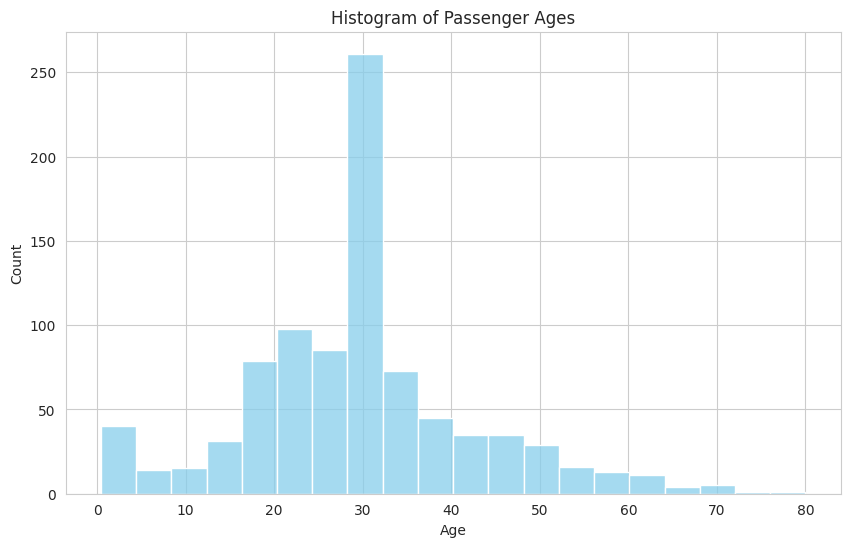

In [9]:
plt.figure(figsize=(10,6))

sns.histplot(df["Age"], bins=20, color="skyblue")

plt.title("Histogram of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Count")

plt.show()

##**Insight**
Most passengers were between 20 and 40 years old.

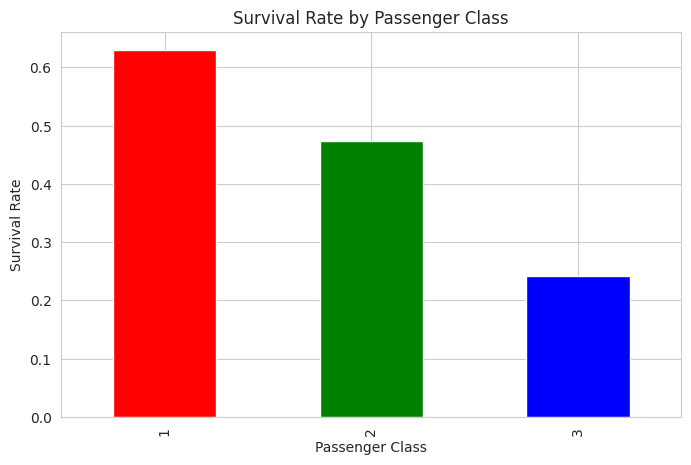

In [10]:
# Visualization by barplot
plt.figure(figsize=(8,5))

survival_by_class = df.groupby("Pclass")["Survived"].mean()

survival_by_class.plot(
    kind="bar",
    color=["red","green","blue"]
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")

plt.show()

##**Insight**
First-class passengers had higher survival rates than passengers in lower classes.

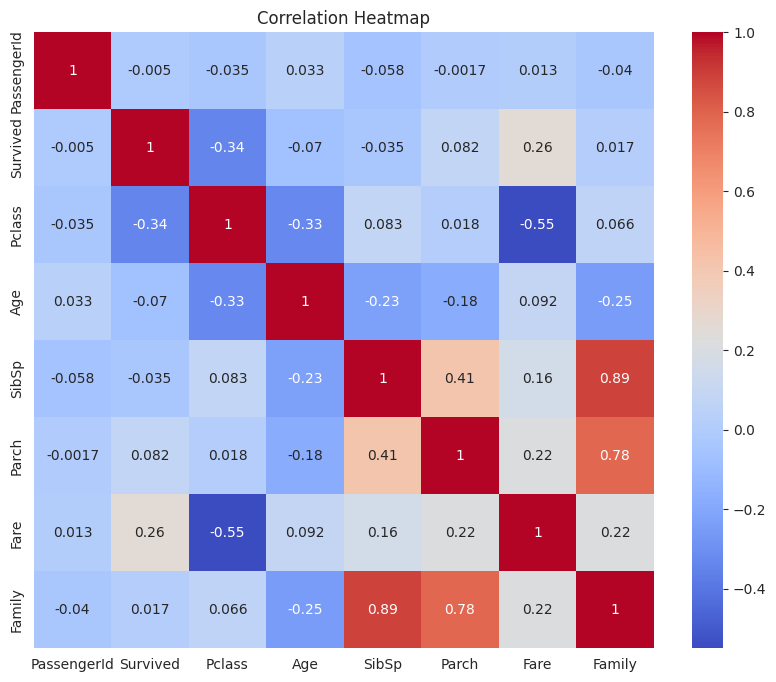

In [11]:
# visualization by heatmap
plt.figure(figsize=(10,8))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

##**Insight**
The strongest factors associated with survival are Passenger Class and Fare, suggesting that socioeconomic status played an important role in survival during the Titanic disaster.

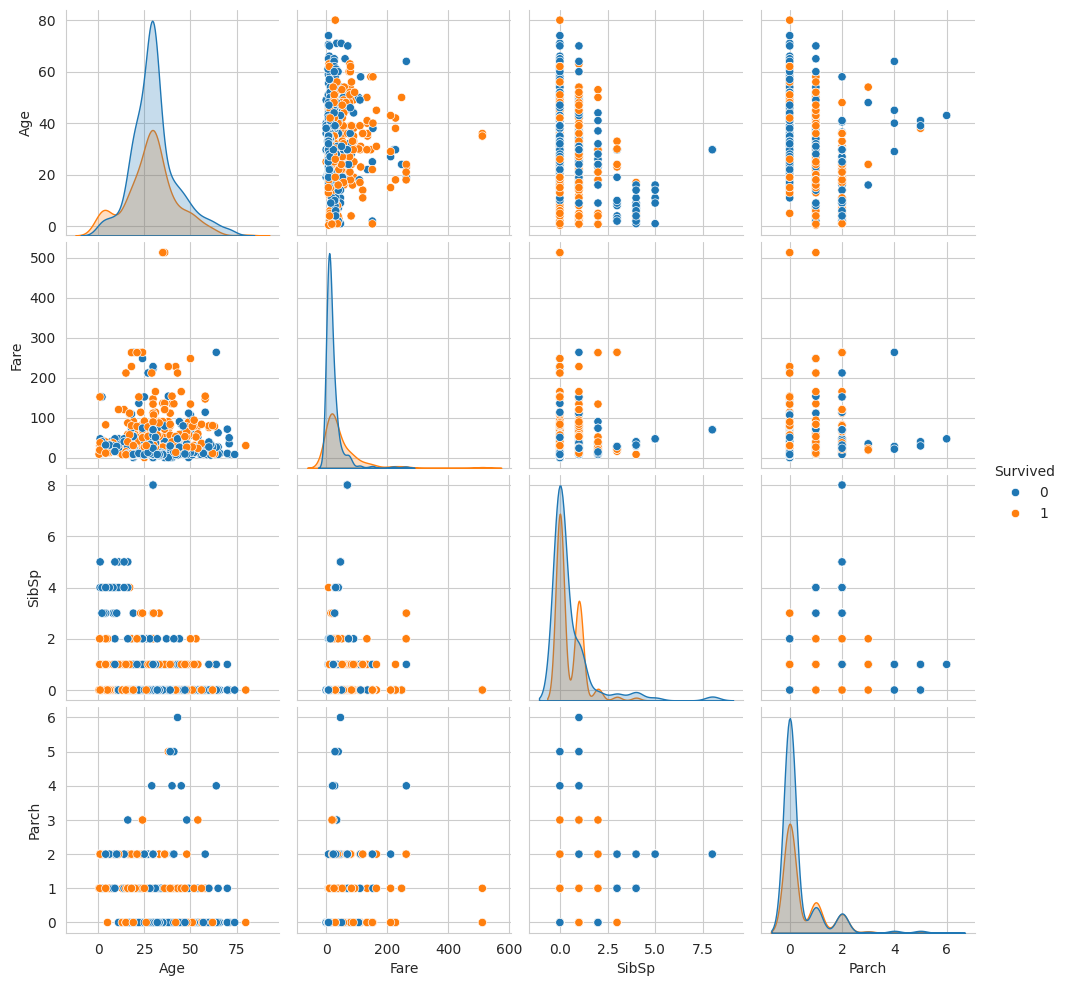

In [13]:
#Pair plot
sns.pairplot(
    df[
        ["Age","Fare","SibSp","Parch","Survived"]
    ],
    hue="Survived"
)

plt.show()

##**Insight**

The pair plot suggests that Fare is more strongly associated with survival than Age, SibSp, or Parch. Passengers who paid higher fares generally experienced higher survival rates, while most passengers traveled alone or with small families. Age shows some influence, particularly for children, but its relationship with survival appears weaker than the effect of fare and passenger class.

##**Task 8: Survival Analysis**

In [14]:
survival_by_sex = df.groupby("Sex")["Survived"].mean()

print("Survival Rate by Sex")
print(survival_by_sex)

survival_by_class = df.groupby("Pclass")["Survived"].mean()

print("\nSurvival Rate by Class")
print(survival_by_class)


Survival Rate by Sex
Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

Survival Rate by Class
Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


##**Insights**
- Female passengers had a significantly higher survival rate.
- First-class passengers were more likely to survive.
- Third-class passengers had the lowest survival rate.

##**Task 9: Age Distribution Analysis**

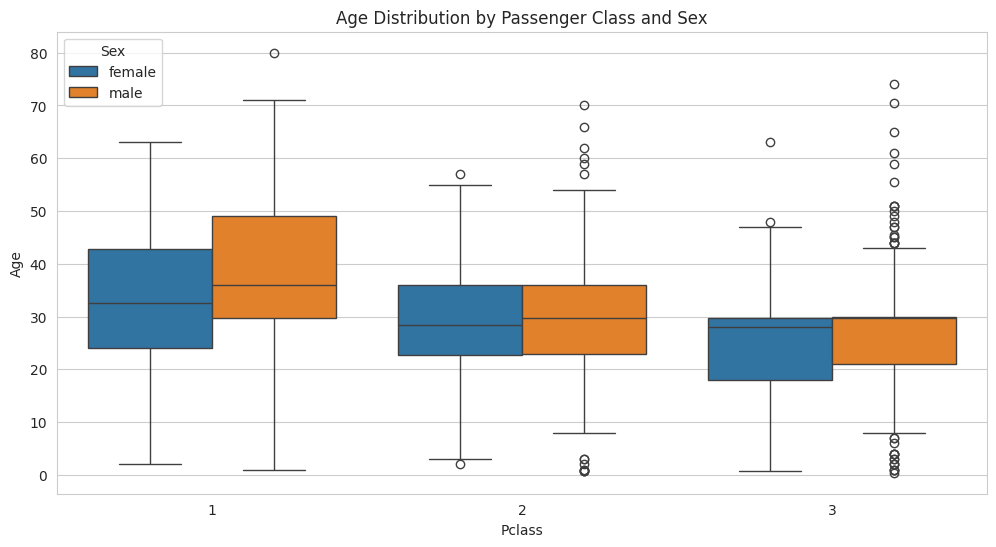

In [15]:
plt.figure(figsize=(12,6))

sns.boxplot(
    data=df,
    x="Pclass",
    y="Age",
    hue="Sex"
)

plt.title("Age Distribution by Passenger Class and Sex")

plt.show()

##**Insight**
Passenger age varied significantly by travel class. First-Class passengers tended to be older and showed greater age diversity, while Third-Class passengers were generally younger. Sex does not appear to have a strong effect on age distribution, whereas passenger class is more closely associated with age differences among Titanic passengers.

##**Task 10: Fare Distribution Analysis**

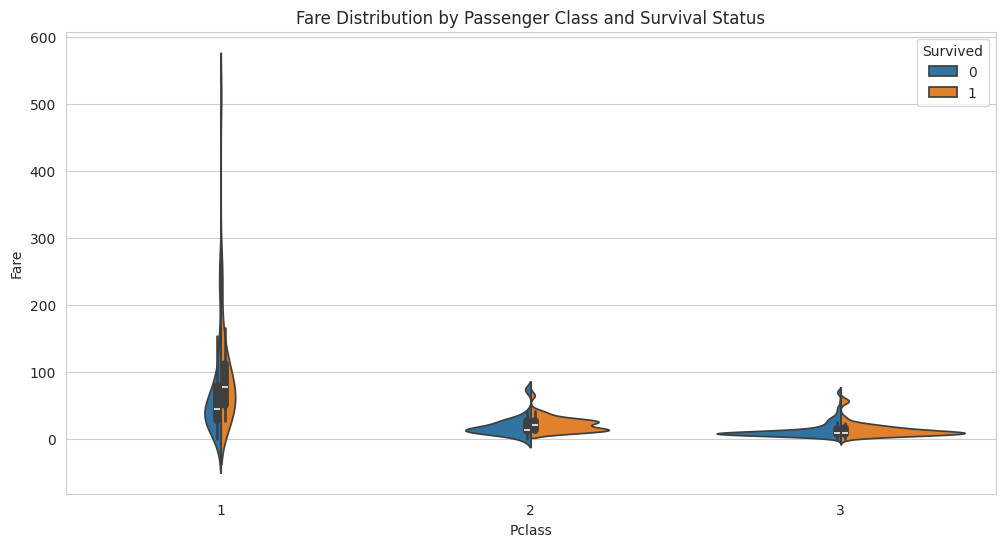

In [16]:
plt.figure(figsize=(12,6))

sns.violinplot(
    data=df,
    x="Pclass",
    y="Fare",
    hue="Survived",
    split=True
)

plt.title("Fare Distribution by Passenger Class and Survival Status")

plt.show()

##**Insight**
Passenger age varied significantly by travel class. First-Class passengers tended to be older and showed greater age diversity, while Third-Class passengers were generally younger. Sex does not appear to have a strong effect on age distribution, whereas passenger class is more closely associated with age differences among Titanic passengers.

##**Conclusion**
The Exploratory Data Analysis (EDA) of the Titanic dataset revealed that passenger survival was strongly influenced by socioeconomic factors. First-Class passengers and those who paid higher fares generally had better survival rates than passengers in lower classes. Female passengers were also more likely to survive than males. While age showed some influence, particularly among children, its impact was weaker compared to passenger class and fare. The analysis also showed that most passengers traveled alone or with small families. Overall, data cleaning, feature engineering, and visualization techniques helped uncover meaningful patterns and provided valuable insights into the factors associated with survival on the Titanic.